# ARAI feature engineering and feature exploration

This notebook computes the model features and the explanatory evidence for every development world, freezes
them on disk, and then explores them against private truth. It follows
`final-spec/components/06-feature-engineering.md` (specification v1.3).

**Two strict phases.**
1. *Features* are computed from the seven operational tables only: no label, persona or group membership.
   Identifiers are used for equality alone. The result is written under `data/artifacts/features/`.
2. *Exploration* joins private truth afterwards, offline, on training worlds only. It can describe a feature,
   but nothing found here is allowed to change a feature without a dated record.

No model is fitted here. The single-feature AUCs below describe the features; they are not model results.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

from arai import dataset, feature_eda, features as F
from arai.generator import load_world
from arai.paths import REPO_ROOT
from arai.settings import load_settings

pd.set_option("display.max_columns", 40, "display.width", 220, "display.precision", 3, "display.max_rows", 60)
experiment = load_settings().experiment
FIXTURES = [f"W{s}" for s in experiment["fixture_seeds"]]
TRAINING = [f"W{s}" for s in experiment["train_seeds"]]
STRESS = [f"W{s}" for s in experiment["stress_seeds"]]
REPORT_DIR = REPO_ROOT / "reports" / "features" / "2026-10-02"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

SURFACE, INK, SECONDARY, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, QUIET = "#2a78d6", "#eb6834", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK, "axes.labelcolor": SECONDARY,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": SECONDARY, "ytick.labelcolor": SECONDARY,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "legend.frameon": False, "axes.titlelocation": "left",
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

## 1. The 18 features

The contract `final-spec/contracts/features.yaml` fixes their order, the rows they are computed on and when
they are null. A null is a real state (for example, no return request at all), never a zero.

In [2]:
contract = pd.DataFrame(__import__("yaml").safe_load((REPO_ROOT / "final-spec/contracts/features.yaml").read_text())["ordered_features"])
display(contract[["name", "definition", "scope", "null"]])

,name,definition,scope,null
0,mature_sale_lines,count mature delivered sale lines,mature_sales,0
1,log_order_count,log1p unique orders with >=1 delivered line,all_delivered,0
2,raw_return_rate,requested mature units / purchased mature units,mature_sales,null if denominator zero
3,expected_return_rate,sum(q*p_cs) / mature units,mature_sales,null if denominator zero
4,residual_z,"(R-E)/sqrt(d*V), two-level self-excluded peers",mature_sales,null if V zero
5,claim_share,transaction claim requested units / all reques...,all_visible_nonwithdrawn_requests,null without requests
6,requested_refund_ratio,requested net value / purchased net value on m...,mature_sales,null if net denominator zero
7,damage_reason_share,customer complaint group units / requested units,all_visible_nonwithdrawn_requests,null without requests
8,bracketing_share,mature units in order/style with >=2 distinct ...,mature_sales,null if no mature units
9,late_window_share,request units with capped window ratio >=.75 /...,all_visible_nonwithdrawn_requests,null without valid timing


## 2. Frozen training reference, then features for every development world

Two things are learned from training worlds and then frozen: the category return rates used when a category has
no peers, and the request-timing baseline used by the wardrobing indicator. Everything else is an aggregate of
the snapshot being scored and is recomputed, never learned.

In [3]:
started = time.time()
reference = dataset.reference_from_worlds(TRAINING)
display(pd.DataFrame(reference.to_dict()).round(3))
built = []
for world_id in FIXTURES + TRAINING + STRESS:
    t = time.time()
    result = dataset.build_features(world_id, reference)
    f = result.features
    built.append({"world": world_id, "customers": len(f), "eligible": int(f["eligible"].sum()), "seconds": round(time.time() - t, 1),
                  "graph_edges": len(result.graph.edges), "identifier_values_dropped": result.graph.dropped_values,
                  "category_fallback_uses": result.fallback_uses})
built = pd.DataFrame(built)
print(f"features frozen for {len(built)} worlds in {time.time() - started:.0f}s under data/artifacts/features/")
display(built)
assert (built["category_fallback_uses"] == 0).all()   # so the features of these worlds do not depend on the reference

,category_rate,latency_median,latency_iqr
Dress,0.247,15.0,15.0
Jacket,0.178,11.0,11.0
Jeans,0.220,8.0,7.0
Shirt,0.203,8.0,7.0
T-shirt,0.180,8.0,7.0


features frozen for 20 worlds in 73s under data/artifacts/features/


,world,customers,eligible,seconds,graph_edges,identifier_values_dropped,category_fallback_uses
0,W2001,1000,521,0.7,116,0,0
1,W2002,1000,573,0.7,91,0,0
2,W2003,1000,518,0.7,74,0,0
3,W2101,10000,5317,3.8,869,2,0
4,W2102,10000,5349,3.7,911,1,0
5,W2103,10000,5240,3.8,1011,1,0
6,W2104,10000,5309,3.9,955,0,0
7,W2105,10000,5259,3.9,920,3,0
8,W2106,10000,5256,3.8,906,2,0
9,W2107,10000,5353,4.0,961,2,0


`category_fallback_uses` is zero everywhere: every category has peers in every world, so no model feature
depends on the frozen reference. That matters later: cross-validation folds can share these feature files
without a held-out world having influenced a training world's features.

## 3. Join private truth (training worlds, offline) and look at the features

In [4]:
frames, wardrobing = [], []
for world_id in TRAINING:
    world = load_world(world_id)
    result = F.compute_features(world.tables, world.snapshot_date, reference)
    frames.append(feature_eda.labelled_frame(world, result))
    wardrobing.append(result.wardrobing.assign(world_id=world_id))
frame = pd.concat(frames, ignore_index=True)
wardrobing = pd.concat(wardrobing, ignore_index=True)
eligible = frame[frame["eligible"]]
print(f"{len(frame):,} customers, {len(eligible):,} eligible, {int(eligible['y_abuse'].sum()):,} eligible abusers")
display(eligible[dataset.MODEL_FEATURES].describe(percentiles=[0.5, 0.95]).T[["count", "mean", "min", "50%", "95%", "max"]])

100,000 customers, 53,024 eligible, 2,876 eligible abusers


,count,mean,min,50%,95%,max
mature_sale_lines,53024.0,20.789,3.000,13.000,58.000,242.000
log_order_count,53024.0,2.364,0.693,2.303,3.714,5.112
raw_return_rate,53024.0,0.193,0.000,0.167,0.500,1.000
expected_return_rate,53024.0,0.201,0.138,0.200,0.228,0.331
residual_z,53024.0,-0.029,-6.100,-0.306,2.975,14.057
claim_share,43036.0,0.110,0.000,0.000,0.667,1.000
requested_refund_ratio,53024.0,0.198,0.000,0.167,0.542,1.000
damage_reason_share,43036.0,0.098,0.000,0.000,0.500,1.000
bracketing_share,53024.0,0.035,0.000,0.000,0.229,1.000
late_window_share,43036.0,0.025,0.000,0.000,0.167,1.000


## 4. Each feature on its own

For every feature, among eligible customers: the AUC where the feature exists (0.5 means no information, below
0.5 means lower values indicate abuse), its range across the ten worlds, how often it is missing for honest
customers and for abusers, and the AUC of the missing-value flag alone.

,auc,auc_min_world,auc_max_world,missing_honest,missing_abuser,auc_of_missing,median_honest,median_abuser
feature,,,,,,,,
requested_refund_ratio,0.792,0.769,0.808,0.000,0.000,NaN,0.157,0.369
residual_z,0.786,0.774,0.798,0.000,0.000,NaN,-0.396,1.437
raw_return_rate,0.786,0.776,0.799,0.000,0.000,NaN,0.167,0.333
claim_share,0.783,0.769,0.799,0.199,0.000,0.400,0.000,0.333
max_identifier_fanout,0.710,0.694,0.734,0.000,0.000,NaN,1.000,3.000
supported_neighbor_count,0.658,0.628,0.675,0.000,0.000,NaN,0.000,0.000
late_window_share,0.629,0.612,0.641,0.199,0.000,0.400,0.000,0.000
occasion_return_share,0.613,0.571,0.648,0.199,0.000,0.400,0.091,0.222
coordinated_claim_share,0.597,0.570,0.623,0.803,0.248,0.223,0.000,0.000


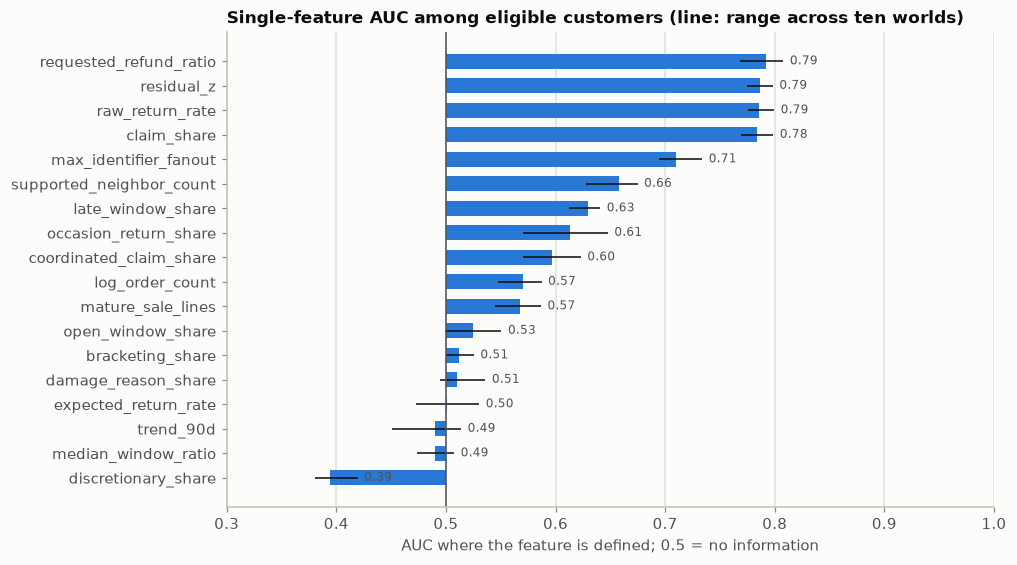

In [5]:
uni = feature_eda.univariate(frame)
display(uni.sort_values("auc", ascending=False))
uni.to_csv(REPORT_DIR / "univariate.csv")

order = uni["auc"].sort_values().index
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.barh(order, uni.loc[order, "auc"] - 0.5, left=0.5, height=0.6, color=BLUE)
ax.hlines(order, uni.loc[order, "auc_min_world"], uni.loc[order, "auc_max_world"], color=INK, linewidth=1)
ax.axvline(0.5, color=SECONDARY, linewidth=1)
for name in order:
    ax.text(max(uni.loc[name, "auc"], uni.loc[name, "auc_max_world"]) + 0.006, name, f"{uni.loc[name, 'auc']:.2f}", va="center", fontsize=8, color=SECONDARY)
ax.set_title("Single-feature AUC among eligible customers (line: range across ten worlds)")
ax.set_xlabel("AUC where the feature is defined; 0.5 = no information")
ax.set_xlim(0.3, 1.0)
ax.grid(axis="y", visible=False)
plt.show()

In [6]:
missing = uni[["missing_honest", "missing_abuser", "auc_of_missing"]].query("missing_honest > 0 or missing_abuser > 0")
display(missing.sort_values("auc_of_missing", ascending=False))

,missing_honest,missing_abuser,auc_of_missing
feature,,,
trend_90d,0.425,0.345,0.460
claim_share,0.199,0.000,0.400
late_window_share,0.199,0.000,0.400
damage_reason_share,0.199,0.000,0.400
median_window_ratio,0.199,0.000,0.400
occasion_return_share,0.199,0.000,0.400
discretionary_share,0.199,0.000,0.400
coordinated_claim_share,0.803,0.248,0.223


The second table is the one to keep in mind for modelling. Where a feature is missing far more often for honest
customers than for abusers, the model can separate the classes from the gap alone: having any return request,
any claim, or any claim with a linked neighbour is itself evidence. That is legitimate behaviour, not a leak,
but it means the missing-value indicators will carry real weight and the explanation shown to an analyst should
say "has claims" rather than only "high claim share".

## 5. Honest customers and abusers on the strongest features

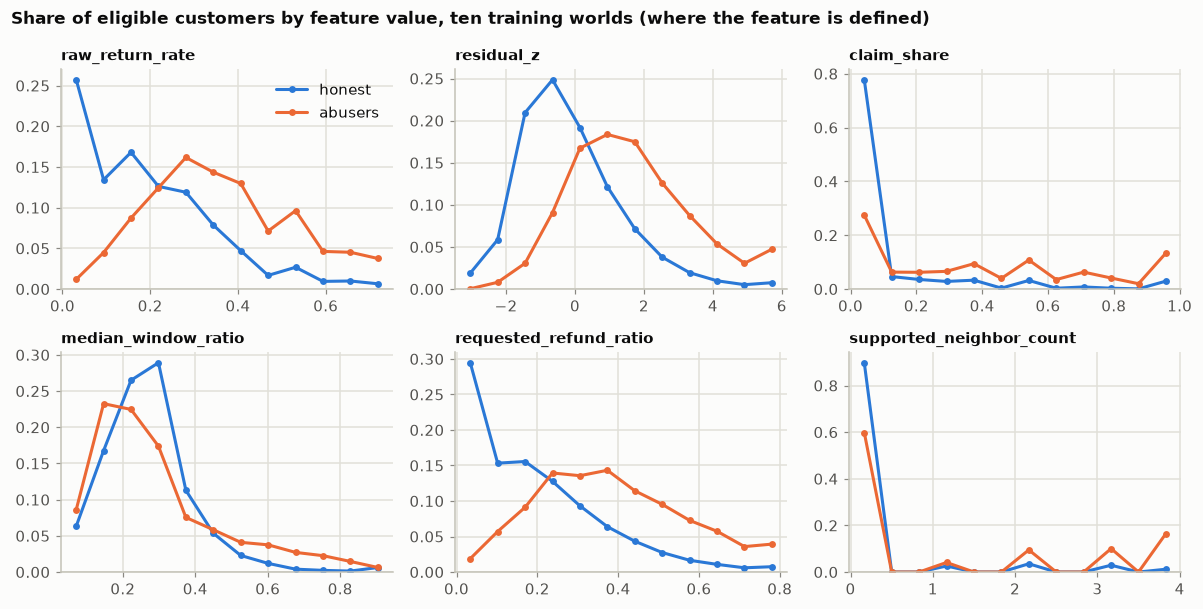

In [7]:
chosen = ["raw_return_rate", "residual_z", "claim_share", "median_window_ratio", "requested_refund_ratio", "supported_neighbor_count"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, name in zip(axes.ravel(), chosen):
    values = eligible[name].dropna()
    lo, hi = values.quantile([0.005, 0.995])
    bins = np.linspace(lo, hi, 13) if hi > lo else np.linspace(lo - 0.5, lo + 0.5, 3)
    for label, mask, colour in (("honest", eligible["y_abuse"] == 0, BLUE), ("abusers", eligible["y_abuse"] == 1, ORANGE)):
        part = eligible.loc[mask, name].dropna().clip(lo, hi)
        share = np.histogram(part, bins=bins)[0] / max(len(part), 1)
        ax.plot((bins[:-1] + bins[1:]) / 2, share, color=colour, marker="o", markersize=3.5, label=label)
    ax.set_title(name, fontsize=10)
    ax.set_ylim(bottom=0)
axes[0, 0].legend(loc="upper right")
fig.suptitle("Share of eligible customers by feature value, ten training worlds (where the feature is defined)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

## 6. Which signal belongs to which behaviour

Mean feature values by behaviour group, eligible customers only. Groups are assigned in the order shown, so each
customer is in exactly one: ring claimants first, then other abusers, then the three honest look-alike groups
the gate protects, then everyone else. This table is the backbone of the explanation for a non-specialist: the
return-rate rule reads only the third row.

In [8]:
profile = feature_eda.group_profile(frame)
columns = ["honest: other", "honest: heavy returner", "honest: defective-product buyer", "honest: household",
           "abuser: solo claims", "abuser: ring claims", "abuser: temporary use", "abuser: claims and temporary use"]
display(profile[[c for c in columns if c in profile]].round(3))
profile.to_csv(REPORT_DIR / "group_profile.csv")

group,honest: other,honest: heavy returner,honest: defective-product buyer,honest: household,abuser: solo claims,abuser: ring claims,abuser: temporary use,abuser: claims and temporary use
mature_sale_lines,16.136,16.946,40.273,16.495,24.492,22.312,24.778,33.580
log_order_count,2.195,2.195,3.048,2.241,2.584,2.439,2.597,2.808
raw_return_rate,0.132,0.520,0.215,0.131,0.348,0.395,0.334,0.418
expected_return_rate,0.200,0.203,0.203,0.200,0.201,0.202,0.201,0.202
residual_z,-0.563,2.866,0.094,-0.581,1.606,1.868,1.466,2.649
claim_share,0.097,0.076,0.069,0.111,0.546,0.609,0.047,0.334
requested_refund_ratio,0.136,0.526,0.221,0.135,0.346,0.425,0.386,0.457
damage_reason_share,0.043,0.069,0.281,0.042,0.048,0.043,0.124,0.067
bracketing_share,0.034,0.040,0.035,0.034,0.033,0.030,0.036,0.050
late_window_share,0.019,0.020,0.021,0.022,0.015,0.019,0.233,0.159


## 7. How the features relate to each other

,feature_a,feature_b,spearman
0,mature_sale_lines,log_order_count,0.972
1,raw_return_rate,requested_refund_ratio,0.948
2,raw_return_rate,residual_z,0.925
3,residual_z,requested_refund_ratio,0.868
4,max_identifier_fanout,supported_neighbor_count,0.812
5,supported_neighbor_count,coordinated_claim_share,0.490
6,max_identifier_fanout,coordinated_claim_share,0.405
7,requested_refund_ratio,occasion_return_share,0.307
8,mature_sale_lines,bracketing_share,0.292
9,mature_sale_lines,damage_reason_share,0.287


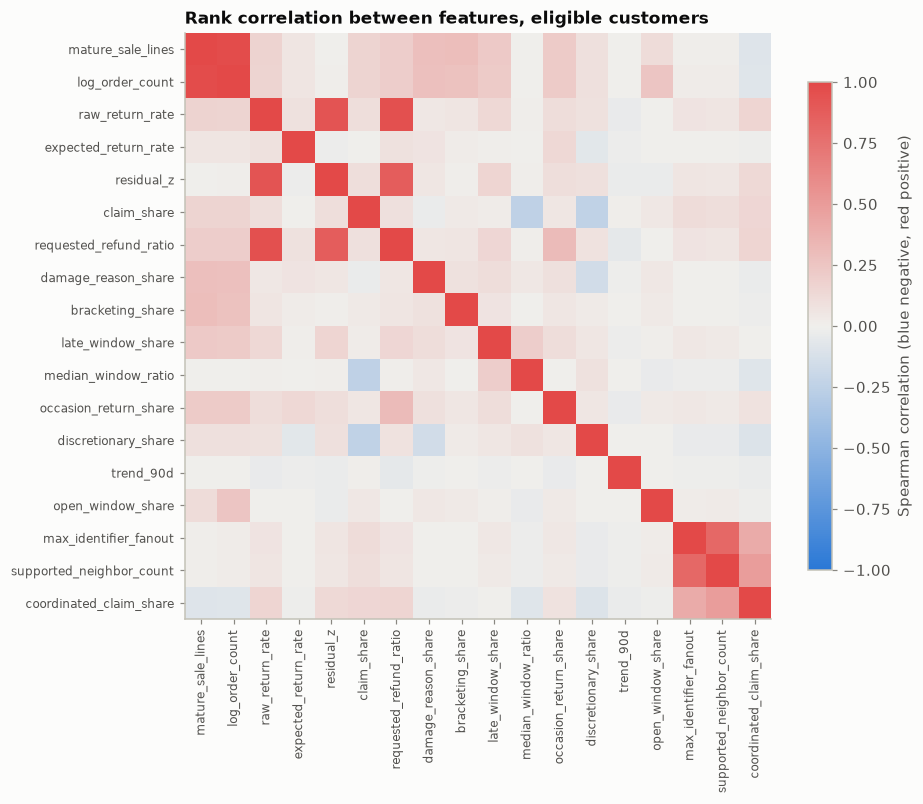

In [9]:
corr = feature_eda.correlations(frame)
display(feature_eda.strongest_pairs(corr))
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(8.6, 7.2))
image = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8, label="Spearman correlation (blue negative, red positive)")
ax.set_title("Rank correlation between features, eligible customers")
plt.show()
corr.to_csv(REPORT_DIR / "correlations.csv")

## 8. Volume as a shortcut

Completed abuse is more common among customers with more orders, simply because they had more chances. The two
volume features carry that. This is the check that the model will not be mostly a volume ranking.

In [10]:
volume = uni.loc[["mature_sale_lines", "log_order_count", "open_window_share", "trend_90d"], ["auc", "auc_min_world", "auc_max_world"]]
display(volume)
by_persona = eligible.groupby("persona")[["raw_return_rate", "residual_z", "claim_share", "supported_neighbor_count"]].mean()
by_persona["customers"] = eligible.groupby("persona").size()
by_persona["abusers"] = eligible.groupby("persona")["y_abuse"].sum()
display(by_persona.round(3))

,auc,auc_min_world,auc_max_world
feature,,,
mature_sale_lines,0.568,0.545,0.587
log_order_count,0.571,0.547,0.587
open_window_share,0.525,0.499,0.551
trend_90d,0.490,0.451,0.514


,raw_return_rate,residual_z,claim_share,supported_neighbor_count,customers,abusers
persona,,,,,,
High_Intensity,0.435,3.235,0.056,0.326,1801,194
Loyalist,0.175,-0.376,0.111,0.252,15647,892
New_Growth,0.172,-0.169,0.141,0.321,2725,155
Occasional,0.156,-0.323,0.138,0.324,19175,900
Seasonal,0.236,0.378,0.083,0.276,13676,735


## 9. The wardrobing indicator against actual temporary use

The indicator is independent of the model score. It cannot establish that a garment was worn; it reports timing
and composition signals. Bands need at least one timing signal.

In [11]:
report = feature_eda.wardrobing_report(frame, wardrobing)
display(report["status_by_truth"]); display(report["bands"].round(3)); display(report["false_alerts"].round(3))
report["bands"].to_csv(REPORT_DIR / "wardrobing_bands.csv", index=False)
report["false_alerts"].to_csv(REPORT_DIR / "wardrobing_false_alerts.csv", index=False)

temporary_use_return,no temporary use,temporary use
status,,
elevated,455,143
insufficient_evidence,9988,0
no_elevated_signal,40529,829
possible,943,137


,band,flagged,true_temporary_use,precision,recall,temporary_use_customers
0,elevated,598,143,0.239,0.129,1109
1,elevated or possible,1678,280,0.167,0.252,1109


,honest_group,customers,alerted,alert_rate
0,any late-in-window request,4183,763,0.182
1,size bracketers,10645,239,0.022
2,all honest eligible,50148,1390,0.028


## 10. Stability across worlds, and a saved summary

In [12]:
per_world = eligible.groupby("world_id")[dataset.MODEL_FEATURES].mean()
spread = pd.DataFrame({"mean": per_world.mean(), "lowest_world": per_world.min(), "highest_world": per_world.max()})
spread["relative_range"] = (spread["highest_world"] - spread["lowest_world"]) / spread["mean"].abs().replace(0, np.nan)
display(spread.round(3))
summary = {"date": "2026-10-02", "specification": "1.3", "training_worlds": TRAINING,
           "customers": int(len(frame)), "eligible": int(len(eligible)), "eligible_abusers": int(eligible["y_abuse"].sum()),
           "category_fallback_uses": int(built["category_fallback_uses"].sum()),
           "univariate_auc": uni["auc"].round(4).to_dict(), "auc_of_missing": uni["auc_of_missing"].dropna().round(4).to_dict(),
           "wardrobing": report["bands"].to_dict(orient="records")}
(REPORT_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=float) + "\n", encoding="utf-8")
print("reports written to", REPORT_DIR.relative_to(REPO_ROOT))

,mean,lowest_world,highest_world,relative_range
mature_sale_lines,20.788,20.485,21.127,0.031
log_order_count,2.364,2.348,2.376,0.012
raw_return_rate,0.193,0.189,0.197,0.039
expected_return_rate,0.201,0.197,0.205,0.042
residual_z,-0.029,-0.038,-0.019,0.656
claim_share,0.110,0.105,0.113,0.070
requested_refund_ratio,0.198,0.192,0.202,0.052
damage_reason_share,0.098,0.094,0.101,0.066
bracketing_share,0.035,0.033,0.037,0.107
late_window_share,0.025,0.023,0.027,0.170


reports written to reports\features\2026-10-02


## Limits

- Single-feature AUCs describe features one at a time on simulated data. They are not model performance, and
  they are measured on the same worlds the generator was explored on.
- The features were designed with knowledge of how the generator works, so strong separation here says the
  features recover the simulation, not that they would work on real returns.
- Findings and any decision they lead to are recorded in `records/2026-10-02-features.md`.